# 🌵 Onde furar os poços? — **Sertão do Pajeú (18 municípios)** com QAOA

Terceiro cluster, e o maior: **18 municípios**. Mesmo problema (Conjunto Dominante Mínimo),
mas agora em **18 qubits** — e aqui a coisa fica interessante, porque é onde o QAOA começa a
**esbarrar nos limites de escala**.

Cidades: Afogados da Ingazeira, Brejinho, Calumbi, Carnaíba, Custódia, Flores, Iguaracy,
Ingazeira, Itapetim, Quixaba, Santa Cruz da Baixa Verde, Santa Terezinha, Serra Talhada,
Solidão, São José do Egito, Tabira, Triunfo, Tuparetama.

> **Spoiler honesto:** o brute force resolve na hora (3 poços). O QAOA de profundidade acessível
> **não crava o ótimo** — mas aprende a cobrir todas as cidades e bate o aleatório. É o retrato
> real da era NISQ.

## 0. Setup, dados e adjacência (Delaunay ∩ < 60 km)

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, itertools as it
import networkx as nx, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from scipy.spatial import Delaunay
from scipy.optimize import minimize

PAL={"otimo":"#159a7c","viavel":"#83c9b6","inviavel":"#e08a7d","escuro":"#264653",
     "accent":"#d98324","cinza":"#9aa4ab","edge":"#dfe4e8"}
INK="#33414a"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,
    "font.size":11,"axes.titlesize":12.5,"axes.titleweight":"bold","axes.labelcolor":INK,
    "axes.edgecolor":"#cfd6db","text.color":INK,"xtick.color":"#6b767d","ytick.color":"#6b767d",
    "axes.spines.top":False,"axes.spines.right":False})
def clean(ax):
    for s in ("top","right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y",color="#eef1f3",lw=1.1); ax.set_axisbelow(True); ax.tick_params(length=0); return ax

data=[("Afogados da Ingazeira",-7.7481283,-37.6346614),("Brejinho",-7.3491144,-37.2871181),
("Calumbi",-7.9396706,-38.1525186),("Carnaíba",-7.805964,-37.7947314),("Custódia",-8.0860251,-37.6400307),
("Flores",-7.862025,-37.9742806),("Iguaracy",-7.8363415,-37.5140407),("Ingazeira",-7.6773108,-37.4598895),
("Itapetim",-7.377426,-37.1888025),("Quixaba",-7.7185273,-37.8484398),("Santa Cruz da Baixa Verde",-7.8185452,-38.1523506),
("Santa Terezinha",-7.37696,-37.47875),("Serra Talhada",-7.9867805,-38.2920294),("Solidão",-7.6008705,-37.6514396),
("São José do Egito",-7.4698369,-37.2746135),("Tabira",-7.583661,-37.537735),("Triunfo",-7.8362959,-38.1042617),
("Tuparetama",-7.6010116,-37.3114417)]
cidades=[d[0] for d in data]; lat=np.array([d[1] for d in data]); lon=np.array([d[2] for d in data])
n=len(cidades); pos={i:(lon[i],lat[i]) for i in range(n)}

def hav(a,b):
    p=np.pi/180;R=6371
    return 2*R*np.arcsin(np.sqrt(np.sin((lat[b]-lat[a])*p/2)**2+np.cos(lat[a]*p)*np.cos(lat[b]*p)*np.sin((lon[b]-lon[a])*p/2)**2))
Dist=np.array([[0 if i==j else hav(i,j) for j in range(n)] for i in range(n)])
tri=Delaunay(np.column_stack([lon,lat])); Adj=np.zeros((n,n),int)
for s in tri.simplices:
    for a,b in it.combinations(s,2):
        if Dist[a,b]<60: Adj[a,b]=Adj[b,a]=1
N={i:sorted([i]+[j for j in range(n) if Adj[i,j]]) for i in range(n)}
g=nx.Graph(); g.add_nodes_from(range(n))
for i in range(n):
    for j in range(i+1,n):
        if Adj[i,j]: g.add_edge(i,j)
print(f"{n} cidades | arestas: {g.number_of_edges()} | componentes: {nx.number_connected_components(g)}")
print("grau (top 5):", sorted(((cidades[i],g.degree(i)) for i in range(n)),key=lambda t:-t[1])[:5])


18 cidades | arestas: 41 | componentes: 1
grau (top 5): [('Quixaba', 7), ('Afogados da Ingazeira', 6), ('Santa Terezinha', 6), ('Tuparetama', 6), ('Calumbi', 5)]


## 1. O grafo de vizinhança

18 municípios formam **um único bloco conectado** (Pajeú é compacto). O tamanho do nó reflete
quantas vizinhas cada cidade tem — **Quixaba** é a mais conectada (grau 7).

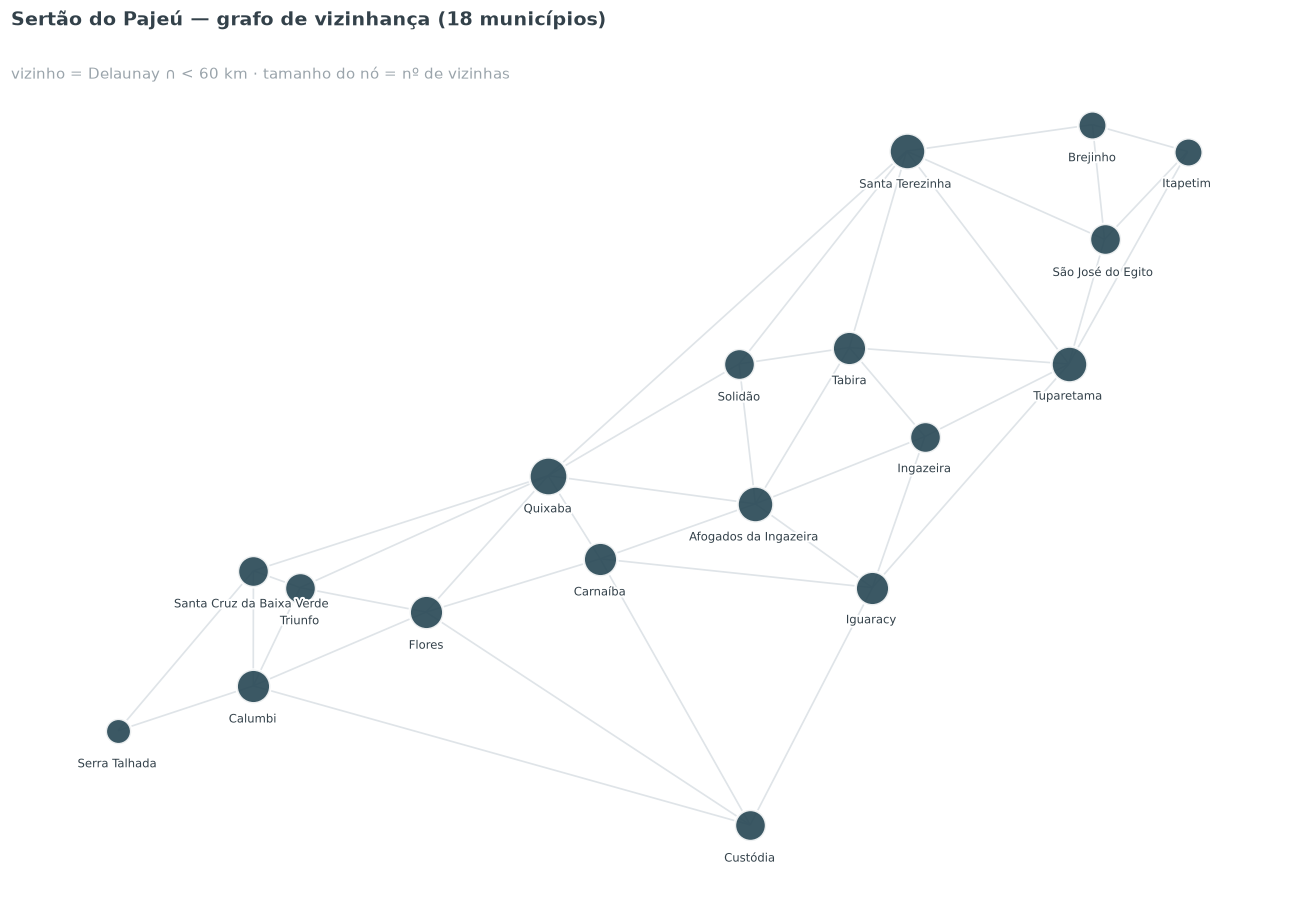

In [2]:
fig,ax=plt.subplots(figsize=(12,8.5))
nx.draw_networkx_edges(g,pos,ax=ax,width=1.1,edge_color=PAL["edge"])
deg=dict(g.degree())
for i in range(n):
    ax.scatter(*pos[i],s=140+70*deg[i],color=PAL["escuro"],edgecolors="white",linewidths=1.8,zorder=3,alpha=0.9)
    t=ax.text(pos[i][0],pos[i][1]-0.028,cidades[i],ha="center",va="top",fontsize=7.6,color=INK,zorder=5)
    t.set_path_effects([pe.withStroke(linewidth=2.6,foreground="white")])
ax.set_title("Sertão do Pajeú — grafo de vizinhança (18 municípios)",loc="left",pad=10)
ax.text(0,0.97,"vizinho = Delaunay ∩ < 60 km · tamanho do nó = nº de vizinhas",
        transform=ax.transAxes,fontsize=10,color=PAL["cinza"],va="top")
mx=(lon.max()-lon.min())*0.10; my=(lat.max()-lat.min())*0.12
ax.set_xlim(lon.min()-mx,lon.max()+mx); ax.set_ylim(lat.min()-my,lat.max()+my); ax.set_axis_off()
plt.tight_layout(); plt.show()


## 2. Modelagem (idêntica)

$$\min \sum_i x_i \quad\text{s.a.}\quad \sum_{j\in N[i]} x_j\ge 1\;\forall i \qquad\Longrightarrow\qquad
H_C=B\sum_i x_i + A\sum_i\prod_{u\in N[i]}(1-x_u)$$

**Diferença prática do 18 qubits:** $H_C$ é diagonal com $2^{18}=262{.}144$ entradas. Construir a
matriz $2^{18}\times2^{18}$ (`to_matrix`) seria inviável (~$10^{11}$ elementos) — então trabalhamos
direto com o **vetor de energias** $E(z)$, que é a diagonal de $H_C$.

In [3]:
A_pen, B_cost = 8.0, 1.0
# energias de TODAS as 2^18 configurações, vetorizado (a diagonal de H_C)
xb=((np.arange(2**n)[:,None]>>np.arange(n))&1).astype(np.int8)
cover=np.zeros((2**n,n),bool)
for i in range(n): cover[:,i]=xb[:,N[i]].any(1)
descob=(~cover).sum(1)
energies=(B_cost*xb.sum(1)+A_pen*descob).astype(float)
feasible=descob==0
print(f"energias calculadas: {energies.size:,} configurações")
print(f"<H> de um chute uniforme: {energies.mean():.1f}  |  fração viável (cobre tudo): {feasible.mean():.3f}")


energias calculadas: 262,144 configurações
<H> de um chute uniforme: 13.3  |  fração viável (cobre tudo): 0.696


## 3. Solução exata — o gabarito

`argmin` sobre as 262 mil energias. Aqui o mínimo é **3 poços** e a solução é **única**.

ótimo: H=3  ->  3 poços (soluções ótimas: 1)
   • poço em Afogados da Ingazeira  cobre ['Afogados da Ingazeira', 'Carnaíba', 'Iguaracy', 'Ingazeira', 'Quixaba', 'Solidão', 'Tabira']
   • poço em Calumbi                cobre ['Calumbi', 'Custódia', 'Flores', 'Santa Cruz da Baixa Verde', 'Serra Talhada', 'Triunfo']
   • poço em São José do Egito      cobre ['Brejinho', 'Itapetim', 'Santa Terezinha', 'São José do Egito', 'Tuparetama']


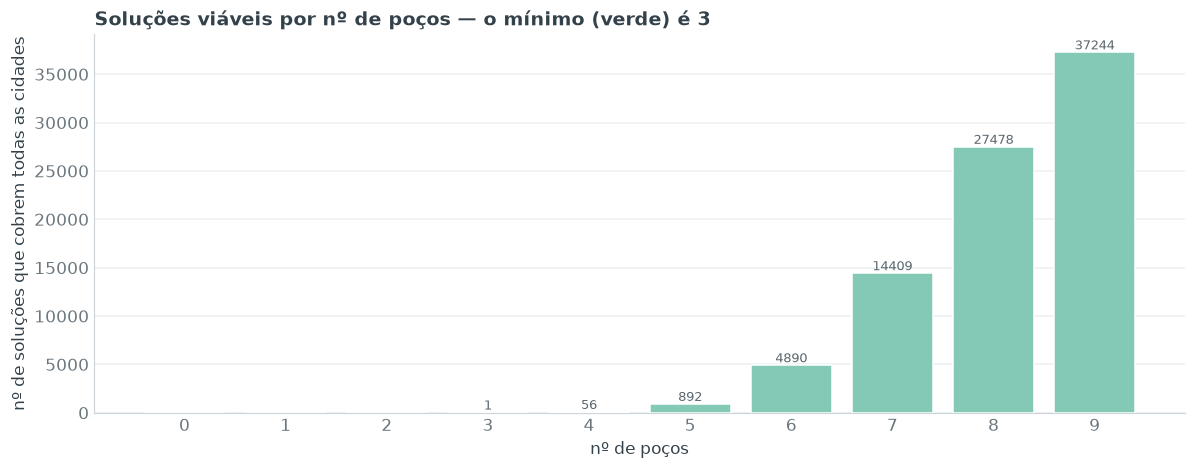

In [4]:
def bits(k): return [(k>>i)&1 for i in range(n)]
def pocos(k): return [cidades[i] for i in range(n) if (k>>i)&1]
melhor=int(np.argmin(energies)); gmin=energies[melhor]
wells=[i for i in range(n) if (melhor>>i)&1]
n_opt=int((energies==gmin).sum())
print(f"ótimo: H={gmin:.0f}  ->  {len(wells)} poços (soluções ótimas: {n_opt})")
for i in wells: print(f"   • poço em {cidades[i]:22s} cobre {sorted(cidades[j] for j in N[i])}")

# paisagem de energia (não dá pra plotar 262k barras -> histograma por nº de poços entre as VIÁVEIS)
fig,ax=plt.subplots(figsize=(11,4.4)); clean(ax)
nw=xb.sum(1)
vals=np.arange(0,10)
counts=[int(((nw==w)&feasible).sum()) for w in vals]
bars=ax.bar(vals,counts,color=[PAL["otimo"] if w==len(wells) else PAL["viavel"] for w in vals],
            edgecolor="white",width=0.8,zorder=3)
ax.set_xlabel("nº de poços"); ax.set_ylabel("nº de soluções que cobrem todas as cidades")
ax.set_title("Soluções viáveis por nº de poços — o mínimo (verde) é 3",loc="left")
for r,c in zip(bars,counts):
    if c: ax.text(r.get_x()+r.get_width()/2,r.get_height(),str(c),ha="center",va="bottom",fontsize=8.5,color="#5b666d")
ax.set_xticks(vals)
plt.tight_layout(); plt.show()


## 4. QAOA no Qiskit (simulador rápido)

$H_C$ é diagonal ⇒ camada de custo = fase $e^{-i\gamma E(z)}$; mixer = $R_X$. **18 qubits** =
vetor de estado de $2^{18}$ amplitudes (roda no laptop, mas cada avaliação é ~40 ms, então
usamos poucas camadas e restarts).

Com 262 mil estados e **um único** ótimo, medir *exatamente* aquele estado é quase impossível.
As métricas que importam na prática são:
- **razão de aproximação** $\langle H\rangle / H_{\text{ótimo}}$ (→1 é ideal);
- **P(viável)** — probabilidade de a medição cobrir todas as cidades;
- **melhor de N medições** — como o QAOA é de fato usado (amostra-se e fica-se com a melhor).

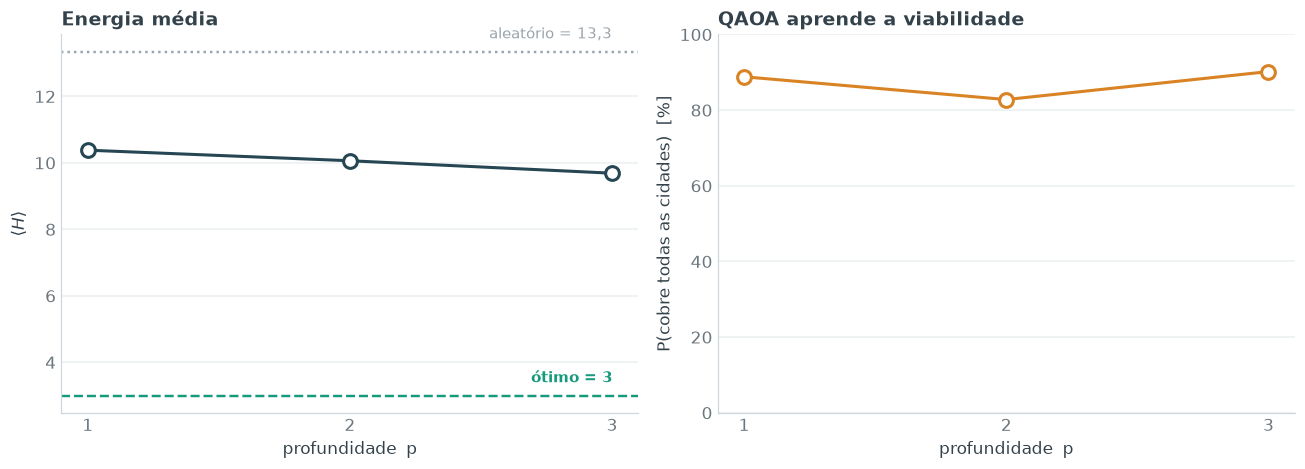

melhor p=3: <H>=9.69  razão de aproximação=3.23
P(viável)=0.902
melhor de 4096 medições  ->  QAOA: H=4   |   aleatório: H=4   (ótimo=3)


In [5]:
def rx_all(state,beta):
    c,s=np.cos(beta),-1j*np.sin(beta); st=state.reshape([2]*n)
    for q in range(n):
        st=np.moveaxis(st,q,0); a0,a1=st[0].copy(),st[1].copy()
        st[0]=c*a0+s*a1; st[1]=s*a0+c*a1; st=np.moveaxis(st,0,q)
    return st.reshape(-1)
def qaoa_probs(prm,p):
    gg,bb=prm[:p],prm[p:]; state=np.ones(2**n,complex)/np.sqrt(2**n)
    for k in range(p): state=state*np.exp(-1j*gg[k]*energies); state=rx_all(state,bb[k])
    return np.abs(state)**2
def exp_H(prm,p): return float(np.sum(qaoa_probs(prm,p)*energies))
def treinar(p,restarts=6,maxiter=120,seed=3):
    rng=np.random.default_rng(seed); best=None
    for _ in range(restarts):
        r=minimize(exp_H,rng.uniform(0,np.pi,2*p),args=(p,),method="COBYLA",options={"maxiter":maxiter})
        if best is None or r.fun<best.fun: best=r
    return best
def melhor_de_N(pr,shots=4096,seed=0):
    return energies[np.random.default_rng(seed).choice(len(pr),size=shots,p=pr)].min()

Ps=[1,2,3]
res={p:treinar(p) for p in Ps}
Hmed=[res[p].fun for p in Ps]
pfeas=[qaoa_probs(res[p].x,p)[feasible].sum() for p in Ps]
uni=np.full(2**n,1/2**n)

fig,(a1,a2)=plt.subplots(1,2,figsize=(12,4.4)); clean(a1); clean(a2)
a1.plot(Ps,Hmed,"-",color=PAL["escuro"],lw=2,zorder=2)
a1.plot(Ps,Hmed,"o",color="white",mec=PAL["escuro"],mew=2,ms=9,zorder=3)
a1.axhline(gmin,ls="--",color=PAL["otimo"],lw=1.6); a1.axhline(energies.mean(),ls=":",color=PAL["cinza"],lw=1.6)
a1.set_xticks(Ps); a1.set_xlabel("profundidade  p"); a1.set_ylabel(r"$\langle H\rangle$")
a1.set_title("Energia média",loc="left")
a1.text(Ps[-1],gmin+0.4,"ótimo = 3",color=PAL["otimo"],ha="right",fontsize=9.5,fontweight="bold")
a1.text(Ps[-1],energies.mean()+0.4,"aleatório = 13,3",color=PAL["cinza"],ha="right",fontsize=9.5)

a2.plot(Ps,[100*p for p in pfeas],"-",color=PAL["accent"],lw=2,zorder=2)
a2.plot(Ps,[100*p for p in pfeas],"o",color="white",mec=PAL["accent"],mew=2,ms=9,zorder=3)
a2.set_xticks(Ps); a2.set_ylim(0,100); a2.set_xlabel("profundidade  p")
a2.set_ylabel("P(cobre todas as cidades)  [%]")
a2.set_title("QAOA aprende a viabilidade",loc="left")
plt.tight_layout(); plt.show()

p_star=min(Ps,key=lambda p:res[p].fun); pr=qaoa_probs(res[p_star].x,p_star)
print(f"melhor p={p_star}: <H>={res[p_star].fun:.2f}  razão de aproximação={res[p_star].fun/gmin:.2f}")
print(f"P(viável)={pr[feasible].sum():.3f}")
print(f"melhor de 4096 medições  ->  QAOA: H={melhor_de_N(pr):.0f}   |   aleatório: H={melhor_de_N(uni):.0f}   (ótimo={gmin:.0f})")


### 4.1 QAOA vs. aleatório — a distribuição de energias

O QAOA desloca a massa de probabilidade para **energias baixas** (mais à esquerda) em relação
ao chute uniforme. Ele não crava o ótimo (energia 3), mas concentra-se na região viável.

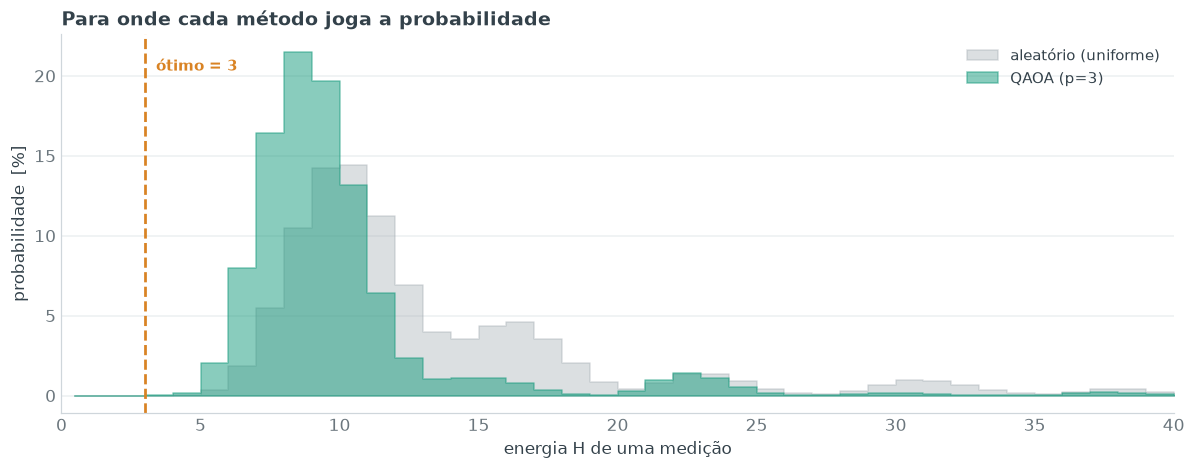

In [6]:
bins=np.arange(0,42)
qa=np.histogram(energies,bins=bins,weights=pr)[0]
un=np.histogram(energies,bins=bins,weights=uni)[0]
ctr=(bins[:-1]+bins[1:])/2
fig,ax=plt.subplots(figsize=(11,4.4)); clean(ax)
ax.fill_between(ctr,0,un*100,step="mid",color=PAL["cinza"],alpha=0.35,label="aleatório (uniforme)")
ax.fill_between(ctr,0,qa*100,step="mid",color=PAL["otimo"],alpha=0.5,label=f"QAOA (p={p_star})")
ax.axvline(gmin,color=PAL["accent"],ls="--",lw=1.8); ax.text(gmin+0.4,ax.get_ylim()[1]*0.9,"ótimo = 3",color=PAL["accent"],fontsize=9.5,fontweight="bold")
ax.set_xlabel("energia H de uma medição"); ax.set_ylabel("probabilidade  [%]")
ax.set_title("Para onde cada método joga a probabilidade",loc="left")
ax.legend(frameon=False,fontsize=10,loc="upper right"); ax.set_xlim(0,40)
plt.tight_layout(); plt.show()


## 5. A solução (exata) no mapa

Os **3 poços** do ótimo e suas áreas de serviço (cada cidade ligada ao poço mais próximo).

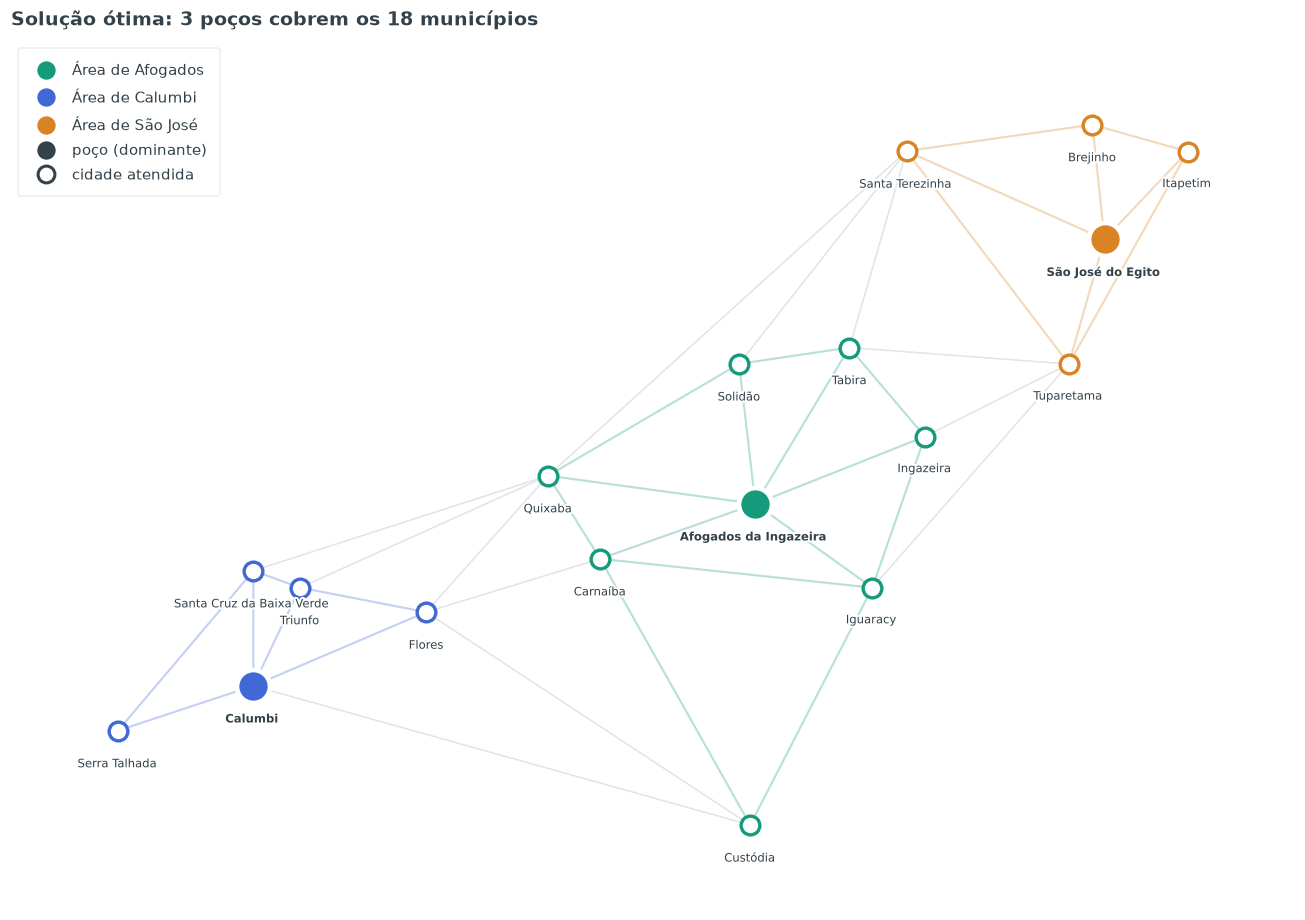

In [7]:
COL={wells[0]:PAL["otimo"], wells[1]:"#4169d6", wells[2]:PAL["accent"]}
terr={i:min(wells,key=lambda w:Dist[i,w]) for i in range(n)}
for w in wells: terr[w]=w
fig,ax=plt.subplots(figsize=(12,8.5))
for u,v in g.edges():
    if terr[u]==terr[v]: ax.plot([pos[u][0],pos[v][0]],[pos[u][1],pos[v][1]],color=COL[terr[u]],alpha=0.30,lw=1.4,zorder=1)
    else: ax.plot([pos[u][0],pos[v][0]],[pos[u][1],pos[v][1]],color=PAL["edge"],lw=1.0,zorder=0)
for i in range(n):
    c=COL[terr[i]]; w=i in wells
    if w:
        ax.scatter(*pos[i],s=560,color="white",zorder=4)
        ax.scatter(*pos[i],s=430,color=c,edgecolors="white",linewidths=2.2,zorder=5)
    else:
        ax.scatter(*pos[i],s=150,color="white",edgecolors=c,linewidths=2.2,zorder=5)
    t=ax.text(pos[i][0],pos[i][1]-0.028,cidades[i],ha="center",va="top",fontsize=7.6,
              fontweight="bold" if w else "normal",color=INK,zorder=6)
    t.set_path_effects([pe.withStroke(linewidth=2.6,foreground="white")])
h=[Line2D([0],[0],marker='o',color='w',markerfacecolor=COL[w],markersize=13,
   label=f"Área de {cidades[w].split(' da')[0].split(' do')[0]}") for w in wells]
h+=[Line2D([0],[0],marker='o',color='w',markerfacecolor=INK,markersize=13,label="poço (dominante)"),
    Line2D([0],[0],marker='o',color='w',markerfacecolor="white",markeredgecolor=INK,markeredgewidth=2,markersize=11,label="cidade atendida")]
lg=ax.legend(handles=h,loc="upper left",frameon=True,fontsize=9.5,borderpad=0.9,labelspacing=0.7)
lg.get_frame().set_edgecolor("#e6e9ec")
ax.set_title("Solução ótima: 3 poços cobrem os 18 municípios",loc="left",pad=10)
mx=(lon.max()-lon.min())*0.10; my=(lat.max()-lat.min())*0.12
ax.set_xlim(lon.min()-mx,lon.max()+mx); ax.set_ylim(lat.min()-my,lat.max()+my); ax.set_axis_off()
plt.tight_layout(); plt.show()


## 6. E no hardware real?

Aos 18 qubits o que trava **não é o número de qubits** (cabem numa QPU de 127), é a
**profundidade**. A camada de custo tem termos de ordem alta (vizinhanças de até 7 vizinhos →
interações de 8 corpos), que viram longas escadas de portas de 2 qubits. Medindo a transpilação
de **uma única** camada (p=1) para a topologia real de um chip IBM (heavy-hex):

In [8]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter as _P
from qiskit.circuit.library import PauliEvolutionGate as _PE
from qiskit.quantum_info import SparsePauliOp as _SPO
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke

def _x(i):
    l=["I"]*n; l[n-1-i]="Z"; return _SPO.from_list([("I"*n,0.5),("".join(l),-0.5)])
_I=_SPO.from_list([("I"*n,1.0)]); _Z=_SPO.from_list([("I"*n,0.0)])
Hc=1.0*sum((_x(i) for i in range(n)),_Z)
for i in range(n):
    pr=_I
    for u in N[i]: pr=pr@(_I-_x(u))
    Hc=Hc+8.0*pr
Hc=Hc.simplify()
ordens=[sum(c!='I' for c in p.to_label()) for p in Hc.paulis]
_gp,_bp=_P('g'),_P('b')
qc=QuantumCircuit(n); qc.h(range(n)); qc.append(_PE(Hc,time=_gp),range(n))
for q in range(n): qc.rx(2*_bp,q)
qc=qc.assign_parameters({_gp:0.4,_bp:0.5})
qt=transpile(qc, FakeSherbrooke(), optimization_level=1)
n2q=sum(qt.count_ops().get(k,0) for k in ("ecr","cz","cx"))
print(f"H_C: {len(Hc)} termos de Pauli | maior ordem: {max(ordens)} corpos")
print(f"circuito p=1 transpilado: profundidade {qt.depth()} | portas de 2 qubits {n2q}")
print(f"fidelidade grosseira (erro 2q ~0,7%): {(1-7e-3)**n2q:.0e}  ->  ruído puro")

H_C: 808 termos de Pauli | maior ordem: 8 corpos
circuito p=1 transpilado: profundidade 20604 | portas de 2 qubits 8483
fidelidade grosseira (erro 2q ~0,7%): 1e-26  ->  ruído puro


**Comparação de escala** (portas de 2 qubits e fidelidade estimada por cluster, p=1):

| Cluster | qubits | portas de 2 qubits | fidelidade estimada |
|---|---:|---:|---:|
| Pajeú-5 | 5 | 152 | **~34%** ✅ roda |
| Araripe-6 | 6 | 211 | **~23%** ⚠️ no limite |
| **Pajeú-18** | 18 | **~8.561** | **~10⁻²⁷** ❌ ruído puro |

Ou seja: o de 18 sairia **indistinguível do acaso**. O que dá pra rodar de verdade é o cluster
**Pajeú-5** — e nós rodamos, no **`ibm_fez`** (processador Heron), 8192 medições:

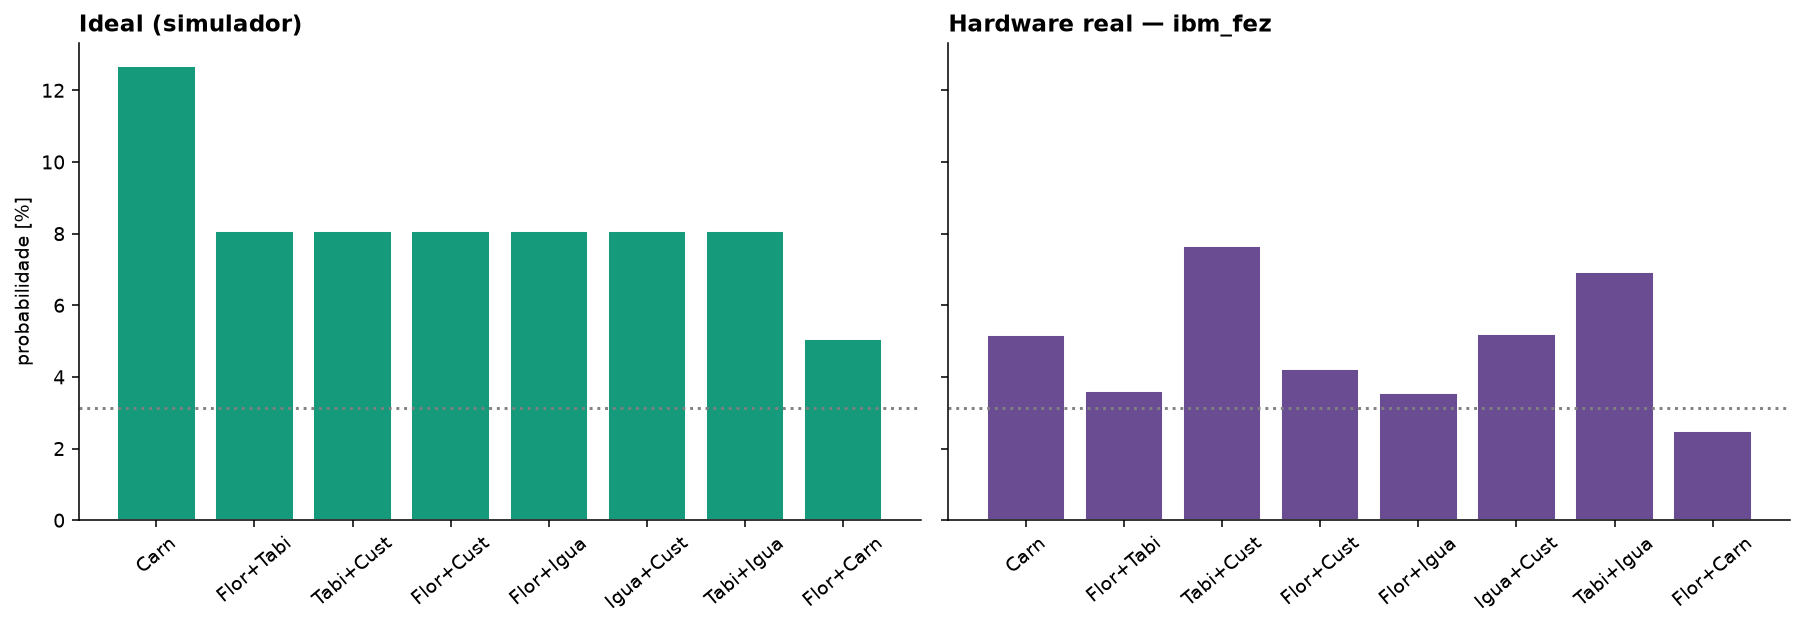

In [9]:
from IPython.display import Image
Image(filename="dados/ibm_pajeu5.png")   # ideal (simulador)  vs  hardware real ibm_fez

No **ideal** (esquerda) o Carnaíba lidera claro. No **hardware real** (direita) o ruído
**achata** a distribuição: o Carnaíba fica acima do acaso (~5% vs 3,1%) mas perde o pico, e o
estado mais frequente vira uma solução viável de 2 poços. É o retrato fiel da era NISQ — o sinal
quântico existe (quase tudo acima do acaso, e são soluções que *cobrem* cidades), mas o ruído
impede o ótimo de cravar. **A 18 qubits nem esse sinal sobreviveria** — por isso ficamos no
simulador para o cluster grande.

## 7. Conclusão — a fronteira de escala

| Cluster | Qubits | Configs | Ótimo exato | QAOA (p baixo) |
|---|---|---|---|---|
| Pajeú (5) | 5 | 32 | 1 poço | **crava** (P≈0,38) |
| Araripe (6) | 6 | 64 | 2 poços | **crava** os 4 ótimos (P≈0,24) |
| Pajeú-18 | 18 | 262.144 | **3 poços** | **não crava** — vira heurística |

**O que aprendemos com o 18:**
- O **brute force ainda vence** — 262 mil configurações é trivial para um laptop.
- O QAOA de profundidade acessível **não recupera o ótimo único**, mas (a) bate o aleatório em
  ⟨H⟩ e (b) **aprende a restrição de cobertura** (P(viável) ≈ 85-90%). É um bom heurístico, não
  um solucionador exato — o retrato fiel da era NISQ.
- **Quando o quântico valeria a pena?** Só em instâncias grandes o bastante para o brute force
  explodir ($2^n$), com circuitos mais profundos e hardware com correção de erro. Aos 18 qubits
  estamos no vale onde nenhum dos dois domina — exatamente o que a literatura mostra.

**Hardware real (ver seção 6):** 18 qubits cabem numa QPU da IBM, mas a camada de custo transpila
para ~8.500 portas de 2 qubits → ruído puro. O cluster pequeno (Pajeú-5) **rodou de fato** no
`ibm_fez` e mostrou o sinal quântico atenuado pelo ruído — o retrato honesto da era NISQ.

**Próximo passo natural:** comparar com *quantum annealing* (D-Wave), que lida melhor com QUBOs
grandes e é o candidato mais realista para esse tamanho de problema.